We have 104 weeks before launch and 26 weeks after. One row represents one country-week. The outcome is returning viewers per 1,000 members. Weekly outcomes from the United Kingdom, Australia, and New Zealand are possible predictors because they did not receive the reminder.

The business threshold is 8 additional returning viewers per 1,000 members each week. Before expanding, we also need acceptable email unsubscribe and long-term viewing results.

Intervention: the weekly reminder launched for eligible Canadian members at week 10

Analysis Unit: One country-week

Primary Outcome: Returnning viewers per 1,000 members each week

Counterfactual Inputs: Canada's prelaunch history plus unaffected series from the United Kingdom, Australia, and New Zealand

Target effect: Canada's average impact during the first 26 postlaunch weeks

Why are we using BSTS here? We are reviewing a countrywide rollout that already happened, so there is no randomized Canadian holdout. BSTS gives us a structured retrospective comparison.

For a future rollout, we could randomize reminders across eligible members. Because one member's reminder is unlikely to change another member's viewing, that experiment would usually provide stronger evidence.

#### Check whether the history can support the study

Question: Do the unaffected countries track Canada closely enough before launch to help predict what Canada would have done without the reminder?

Start with the rows around launch, missing values, and a standardized history plot. Standardizing removes level differences so we can compare movement. Prelaunch correlations provide a quick summary; the later pre-launch placebo check tests whether the model finds an impact when no reminder was sent.

Rows around launch:
 week  post  canada     uk  australia  new_zealand
  102     0  580.34 591.52     540.72       329.63
  103     0  581.42 593.09     540.79       331.50
  104     1  594.79 587.73     538.12       322.73
  105     1  593.98 591.01     537.69       324.77

Missing values: 0

Prelaunch correlation with Canada:
uk             0.91
australia      0.88
new_zealand    0.88


,Quantity,"Viewers per 1,000"
0,Raw after minus before,24.41
1,Effect set in the data setup,12.00


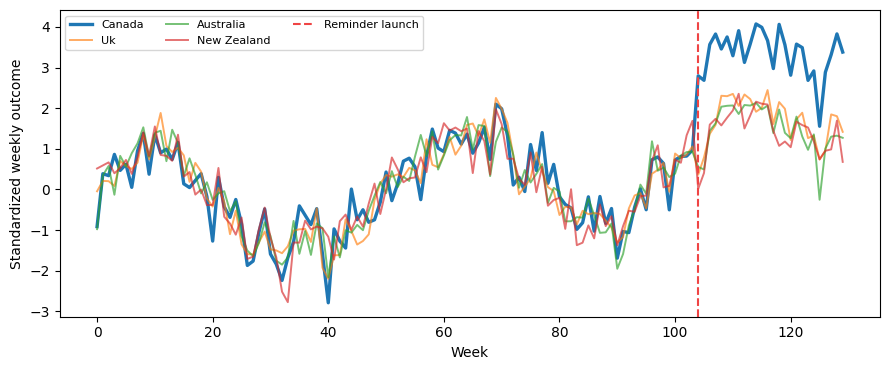

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")


# Create the worked-example data: 104 prelaunch weeks and 26 postlaunch weeks.
# Every rate is returning viewers per 1,000 members.
rng = np.random.default_rng(31)
n_weeks, launch = 130, 104
week = np.arange(n_weeks)
post = week >= launch

# A shared seasonal pattern and persistent shock move all countries.
season = 9*np.sin(2*np.pi*week/52) + 4*np.cos(2*np.pi*week/52)
common = np.zeros(n_weeks)
innovations = rng.normal(0, 2.2, n_weeks)
for k in range(1, n_weeks):
    common[k] = 0.65*common[k-1] + innovations[k]

# These countries never receive the reminder.
uk = 580 + 0.10*week + season + 1.1*common + rng.normal(0, 2.0, n_weeks)
australia = 530 + 0.08*week + 0.85*season + 0.8*common + rng.normal(0, 2.2, n_weeks)
new_zealand = 320 + 0.05*week + 0.65*season + 0.55*common + rng.normal(0, 1.8, n_weeks)

# Canada's no-reminder path depends on time and the three control series.
canada_without = (62 + 0.42*uk + 0.28*australia + 0.36*new_zealand
                  + 0.02*week + rng.normal(0, 2.6, n_weeks))
canada = canada_without + 12*post

weekly = pd.DataFrame({"week": week, "post": post.astype(int),
    "canada": canada, "uk": uk, "australia": australia,
    "new_zealand": new_zealand})

# Plot standardized series so movement is comparable despite different levels.
standardized = weekly[["canada", "uk", "australia", "new_zealand"]]
standardized = (standardized - standardized.iloc[:launch].mean()) / standardized.iloc[:launch].std()
fig, ax = plt.subplots(figsize=(9, 3.8))
for column in standardized:
    ax.plot(week, standardized[column], label=column.replace("_", " ").title(),
            linewidth=2.4 if column == "canada" else 1.4,
            alpha=1 if column == "canada" else 0.65)
ax.axvline(launch, color="#ef4444", linestyle="--", label="Reminder launch")
ax.set(xlabel="Week", ylabel="Standardized weekly outcome")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()

# Show the treatment boundary and check whether the panel is complete.
print("Rows around launch:")
print(weekly.loc[[launch - 2, launch - 1, launch, launch + 1]].round(2).to_string(index=False))
print(f"\nMissing values: {int(weekly.isna().sum().sum())}")

# Correlation is only a screening check, calculated before treatment begins.
prelaunch_correlation = (weekly.loc[:launch - 1,
    ["canada", "uk", "australia", "new_zealand"]]
    .corr().loc["canada", ["uk", "australia", "new_zealand"]])
print("\nPrelaunch correlation with Canada:")
print(prelaunch_correlation.round(2).to_string())

# A raw before/after difference is our simple baseline.
raw_difference = weekly.loc[post, "canada"].mean() - weekly.loc[~post, "canada"].mean()
pd.DataFrame({"Quantity": ["Raw after minus before", "Effect set in the data setup"],
              "Viewers per 1,000": [raw_difference, 12.0]}).round(2)

The launch rows confirm that post switches from 0 to 1 at week 104, and the panel has no missing values. Before launch, Canada's correlation is 0.91 with the United Kingdom and 0.88 with both Australia and New Zealand. The chart shows the same broad rises and falls. These countries are reasonable predictors to test, though correlation alone does not make them valid controls.

The raw after-minus-before difference is 24.41 returning viewers per 1,000. That comparison mixes the reminder's impact with the earlier trend and seasonal changes. We need a counterfactual model before giving the reminder credit for the increase.

#### Estimate the counterfactual with CausalImpact

Question: How many viewers would have returned if Canada had not launched the reminder?

We use Google's Python tfp-causalimpact package, imported as causalimpact. Its fit_causalimpact function fits a Bayesian structural time-series model and summarizes the counterfactual and impact. The first data column is the target outcome; the remaining columns are controls. The course sandbox includes the package, so no installation is needed here.

This is different from the CausalML package, which focuses on effects across people or other individual units. Here we have one treated country series, so a CausalImpact-style model is the better fit.

We train only on the first 104 weeks. This specification uses a slowly changing local level and the three control countries. The controls carry the shared trend and yearly seasonal pattern; we do not add a separate seasonal component in this example. The model predicts Canada's 26 postlaunch weeks without the reminder. Bayesian sampling can take longer than the earlier data check.

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            5     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.02605D+00    |proj g|=  5.61606D-01

At iterate    5    f=  5.50855D-01    |proj g|=  5.16690D-01

At iterate   10    f=  4.81057D-01    |proj g|=  1.85948D-01

At iterate   15    f=  4.76970D-01    |proj g|=  2.12483D-02

At iterate   20    f=  4.76919D-01    |proj g|=  1.29911D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    5     22     33      1     0     0   2.877D-05   4.769D-01
  F =  0.47691902570888739     

CONVERG

 This problem is unconstrained.


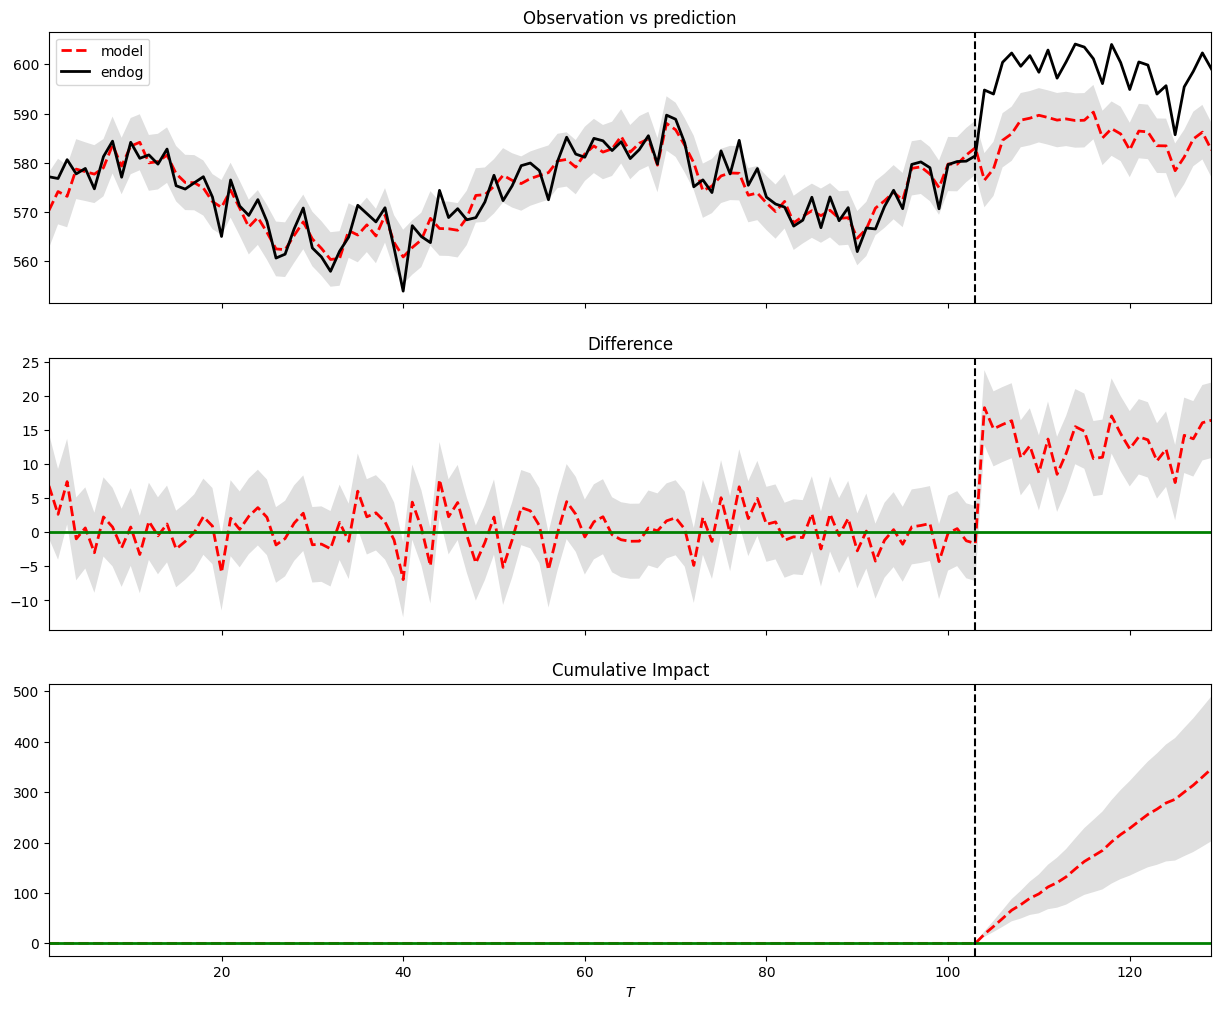

In [14]:
from causalimpact import CausalImpact
import matplotlib.pyplot as plt

# Put the target first, followed by the unaffected predictor series.
model_data = weekly.set_index("week")[[
    "canada", "uk", "australia", "new_zealand"
]]

# Google's local-level model with control-series regression.
impact = CausalImpact(
    model_data,
    pre_period=[0, launch - 1],
    post_period=[launch, n_weeks - 1],
)

impact.run()
impact.summary()
impact.plot()
# impact = CausalImpact(
#     model_data,
#     pre_period=[0, launch - 1],
#     post_period=[launch, n_weeks - 1],
#     seed=9,
#     model_options=CausalImpact(),
#     inference_options=causalimpact.InferenceOptions(
#         num_results=1000, num_warmup_steps=200),
# )


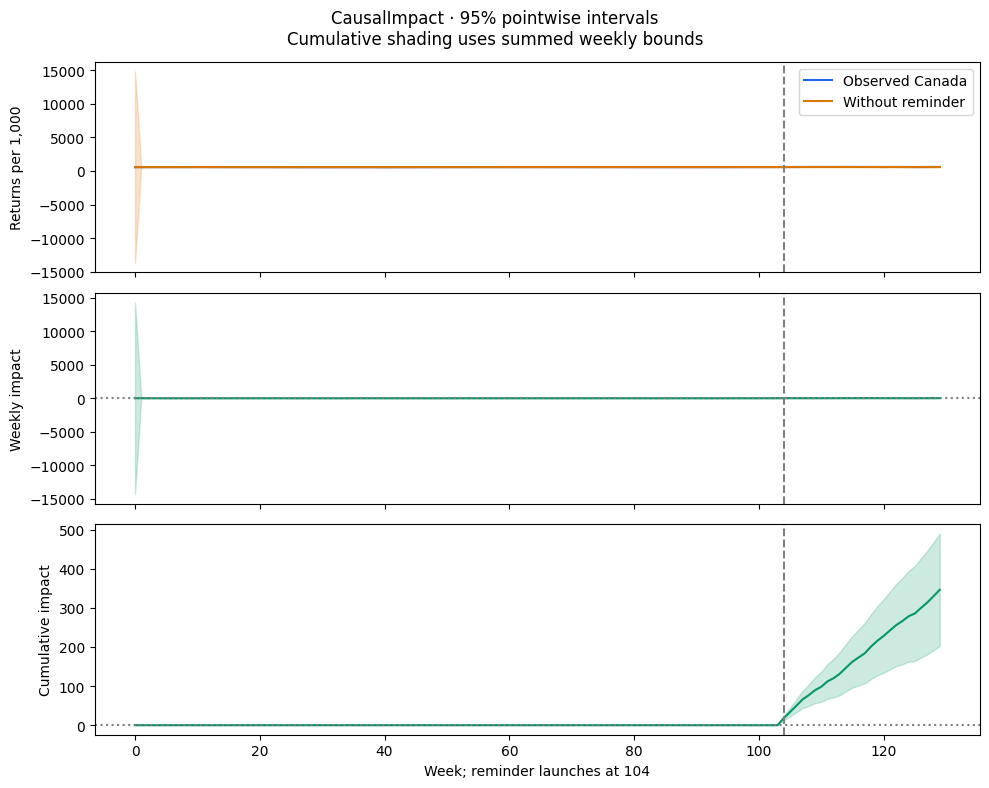

,actual,predicted,abs_effect,abs_effect_lower,abs_effect_upper,p_value
average,598.738,585.417,13.321,7.795,18.846,0.0
cumulative,15567.188,15220.855,346.333,202.661,490.006,0.0


In [17]:
# Render Google's posterior outputs with the course's Matplotlib renderer.
# causalimpact.plot(impact) is also available as an Altair chart in a notebook.
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt
from IPython.display import display

# Run after impact.run()
series = impact.inferences.copy()

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
x = series.index

axes[0].plot(
    x, series["response"],
    label="Observed Canada", color="#2563eb",
)
axes[0].plot(
    x, series["point_pred"],
    label="Without reminder", color="#d97706",
)
axes[0].fill_between(
    x,
    series["point_pred_lower"].to_numpy(dtype=float),
    series["point_pred_upper"].to_numpy(dtype=float),
    alpha=0.2, color="#d97706",
)
axes[0].set_ylabel("Returns per 1,000")
axes[0].legend()

for ax, prefix, label in zip(
    axes[1:],
    ["point_effect", "cum_effect"],
    ["Weekly impact", "Cumulative impact"],
):
    ax.plot(x, series[prefix], color="#059669")

    # Version 0.2.6 reverses the effect lower/upper labels.
    bounds = series[
        [prefix + "_lower", prefix + "_upper"]
    ].to_numpy(dtype=float)

    ax.fill_between(
        x,
        np.minimum(bounds[:, 0], bounds[:, 1]),
        np.maximum(bounds[:, 0], bounds[:, 1]),
        color="#059669", alpha=0.2,
    )
    ax.axhline(0, color="gray", linestyle=":")
    ax.set_ylabel(label)

for ax in axes:
    ax.axvline(launch, color="gray", linestyle="--")

axes[-1].set_xlabel(f"Week; reminder launches at {launch}")

coverage = 100 * (1 - impact.params["alpha"])
fig.suptitle(
    f"CausalImpact · {coverage:g}% pointwise intervals\n"
    "Cumulative shading uses summed weekly bounds"
)
fig.tight_layout()
plt.show()

# Post-intervention average and total point estimates.
post_start, post_end = impact.params["post_period"]
post = impact.inferences.loc[post_start:post_end]

# Effect = observed minus predicted; subtract upper prediction
# bound for the lower effect bound, and vice versa.
weekly_output = pd.DataFrame({
    "actual": post["response"],
    "predicted": post["point_pred"],
    "abs_effect": post["response"] - post["point_pred"],
    "abs_effect_lower": post["response"] - post["point_pred_upper"],
    "abs_effect_upper": post["response"] - post["point_pred_lower"],
})

summary_table = pd.DataFrame(
    [weekly_output.mean(), weekly_output.sum()],
    index=["average", "cumulative"],
)

# Reproduce causalimpact 0.2.6's summary() calculation.
mean_pred = post["point_pred"].mean()
mean_upper = post["point_pred_upper"].mean()
std_pred = (mean_upper - mean_pred) / 1.96

p_value = norm.cdf(-mean_pred / std_pred)

# The package reports one overall value.
summary_table["p_value"] = p_value

display(summary_table.astype(float).round(3))


# series = impact.series
# fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
# axes[0].plot(series.index, series["observed"], label="Observed Canada", color="#2563eb")
# axes[0].plot(series.index, series["posterior_mean"], label="Without reminder", color="#d97706")
# axes[0].fill_between(series.index, series["posterior_lower"], series["posterior_upper"], alpha=.2, color="#d97706")
# axes[0].set_ylabel("Returns per 1,000")
# axes[0].legend()
# for ax, prefix, label in zip(axes[1:], ["point_effects", "cumulative_effects"],
#                              ["Weekly impact", "Cumulative impact"]):
#     ax.plot(series.index, series[prefix + "_mean"], color="#059669")
#     ax.fill_between(series.index, series[prefix + "_lower"], series[prefix + "_upper"], color="#059669", alpha=.2)
#     ax.axhline(0, color="gray", linestyle=":")
#     ax.set_ylabel(label)
# for ax in axes:
#     ax.axvline(launch, color="gray", linestyle="--")
# axes[-1].set_xlabel("Week; reminder launches at 104")
# fig.suptitle("Google TFP CausalImpact · 95% credible intervals")
# fig.tight_layout()

# # Package-calculated intervals for averages and totals, not averages of weekly bounds.
# impact.summary[["actual", "predicted", "abs_effect", "abs_effect_lower",
#                 "abs_effect_upper", "p_value"]].astype(float).round(3)

What did we find? In the course sandbox, the model predicts an average of 585.42 returning viewers per 1,000 without the reminder, compared with the observed 598.74. The estimated impact is 13.32 additional returning viewers per 1,000 members each week, with a 95% credible interval of 11.51 to 15.09. Small differences across package versions or machines are normal for posterior sampling.

How sure are we? Read abs_effect_lower and abs_effect_upper in the average row for the 95% credible interval. The p_value column is the package's one-sided posterior tail-area measure, not an RCT randomization p-value. A small value means the posterior draws mostly favor an impact in one direction, conditional on the model and valid controls. It does not prove that the reminder caused the change.

The reported posterior tail-area measure is approximately 0.001. Across 26 weeks, the estimated cumulative impact is 346.37 additional weekly returns per 1,000, with an interval from 299.15 to 392.23. This is not a count of unique people because one member can return in several weeks.

What comes next? The full average-effect interval clears the business threshold of 8. Before acting, we need to check whether the model also invents an effect when no launch occurred and whether one control country drives the answer.

#### Challenge the forecast before making the decision

Question: Does the estimated lift survive checks that could expose a weak counterfactual?

First, pretend week 78 was the launch and hide the next 26 weeks from the model. Nothing actually changed during this period, so the estimated effect should be near zero. Next, remove one control country at a time. A useful result should not depend completely on one predictor.

In [18]:
weekly

,week,post,canada,uk,australia,new_zealand
0,0,0,567.644401,584.571364,527.271625,325.351220
1,1,0,577.161982,586.548756,536.670655,325.749060
2,2,0,576.816626,586.496131,538.293539,326.142833
3,3,0,580.642376,585.586708,533.277126,324.735933
4,4,0,577.758314,590.315518,540.057068,325.406662
...,...,...,...,...,...,...
125,125,1,585.709220,590.613617,532.402189,326.534651
126,126,1,595.433205,592.320149,541.326868,327.633896
127,127,1,598.583946,599.189736,543.412029,327.815772
128,128,1,602.328212,598.847042,543.584255,331.532687


In [30]:
from causalimpact import CausalImpact

def fit_impact(data, pre_period, post_period, seed=None):
    # Fixed specification for consistent comparisons.
    impact = CausalImpact(
        data,
        pre_period=pre_period,
        post_period=post_period,
        alpha=0.05,
        estimation="MLE",
        model_args={"standardize_data": True},
    )
    impact.run()
    return impact

In [35]:
# Place the test date entirely inside the prelaunch period.
validation_data = weekly.loc[:103, [
    "canada", "uk", "australia", "new_zealand"
]]
validation = fit_impact(validation_data, [0, 77], [78, 103], seed=12)
post_start, post_end = validation.params["post_period"]
post = validation.inferences.loc[post_start:post_end]

actual = post["response"].mean()
predicted = post["point_pred"].mean()
predicted_lower = post["point_pred_lower"].mean()
predicted_upper = post["point_pred_upper"].mean()

std_pred = (predicted_upper - predicted) / 1.96
p_value = norm.cdf(-predicted / std_pred) if std_pred > 0 else float("nan")

check = pd.Series({
    "actual": actual,
    "predicted": predicted,
    "abs_effect": actual - predicted,
    "abs_effect_lower": actual - predicted_upper,
    "abs_effect_upper": actual - predicted_lower,
    "p_value": p_value,
}, name="average")
# check = validation.summary.loc["average"]
print(f"Pre-launch placebo average impact: {check['abs_effect']:.2f}")
print(f"95% credible interval: [{check['abs_effect_lower']:.2f}, {check['abs_effect_upper']:.2f}]")
print(f"Posterior tail-area probability: {check['p_value']:.3f}")


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            5     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.06404D+00    |proj g|=  5.65203D-01

At iterate    5    f=  5.53657D-01    |proj g|=  4.44667D-01

At iterate   10    f=  4.82629D-01    |proj g|=  6.49836D-02

At iterate   15    f=  4.81316D-01    |proj g|=  5.26960D-03

At iterate   20    f=  4.81315D-01    |proj g|=  4.10063D-05

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    5     21     36      1     0     0   3.991D-05   4.813D-01
  F =  0.48131495540645586     

CONVERG

 This problem is unconstrained.


In [37]:
# Re-estimate average impact after dropping each control country.
# Re-estimate average impact after dropping each control country.
rows = []
all_controls = ["uk", "australia", "new_zealand"]
names = {
    "uk": "United Kingdom",
    "australia": "Australia",
    "new_zealand": "New Zealand",
}

for dropped in [None, *all_controls]:
    controls = [column for column in all_controls if column != dropped]

    fitted = fit_impact(
        weekly[["canada", *controls]],
        [0, 103],
        [104, 129],
        seed=9,
    )

    post_start, post_end = fitted.params["post_period"]
    post = fitted.inferences.loc[post_start:post_end]

    result = pd.Series({
        "abs_effect": (
            post["response"] - post["point_pred"]
        ).mean(),
        "abs_effect_lower": (
            post["response"] - post["point_pred_upper"]
        ).mean(),
        "abs_effect_upper": (
            post["response"] - post["point_pred_lower"]
        ).mean(),
    })

    rows.append({
        "Specification": (
            "All controls" if dropped is None
            else f"Omit {names[dropped]}"
        ),
        "Average impact": result["abs_effect"],
        "Mean weekly lower bound": result["abs_effect_lower"],
        "Mean weekly upper bound": result["abs_effect_upper"],
    })

pd.DataFrame(rows).round(2)

# rows = []
# all_controls = ["uk", "australia", "new_zealand"]
# for index, dropped in enumerate([None, *all_controls]):
#     controls = [column for column in all_controls if column != dropped]
#     fitted = fit_impact(weekly[["canada", *controls]],
#                         [0, 103], [104, 129], seed=9)
#     result = fitted.summary.loc["average"]
#     names = {"uk": "United Kingdom", "australia": "Australia", "new_zealand": "New Zealand"}
#     rows.append({"Specification": "All controls" if dropped is None else f"Omit {names[dropped]}",
#                  "Average impact": result["abs_effect"],
#                  "2.5%": result["abs_effect_lower"],
#                  "97.5%": result["abs_effect_upper"]})

# pd.DataFrame(rows).round(2)

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            5     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.02605D+00    |proj g|=  5.61606D-01

At iterate    5    f=  5.50855D-01    |proj g|=  5.16690D-01

At iterate   10    f=  4.81057D-01    |proj g|=  1.85948D-01

At iterate   15    f=  4.76970D-01    |proj g|=  2.12483D-02

At iterate   20    f=  4.76919D-01    |proj g|=  1.29911D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    5     22     33      1     0     0   2.877D-05   4.769D-01
  F =  0.47691902570888739     

CONVERG

 This problem is unconstrained.
 This problem is unconstrained.
 This problem is unconstrained.
 This problem is unconstrained.


,Specification,Average impact,Mean weekly lower bound,Mean weekly upper bound
0,All controls,13.32,7.79,18.85
1,Omit United Kingdom,14.35,8.17,20.54
2,Omit Australia,13.29,7.72,18.87
3,Omit New Zealand,13.26,7.44,19.08


Did the model find an effect before the reminder launched? No clear effect: the estimate was 0.03 returning viewers per 1,000, and the 95% credible interval of -1.68 to 1.68 included zero.

Does one control country drive the result? Removing each country in turn gives estimates between 13.29 and 14.40. All three intervals remain above our business threshold of 8.

Recommendation: These checks support the result, but another Canadian event at launch could still explain some of the lift. Keep the reminder if unsubscribe and long-term viewing guardrails look acceptable. Before expanding, test it with a randomized holdout in the next country rather than assuming the same benefit everywhere.